# Week 6 - Data Manipulation with Pandas

**Paññāsāstra University of Cambodia**
**Course:** Data Analysis and Visualization (3 credits)
**Chapter 6 - Data Manipulation with Pandas**

---

## Session topics (from the course outline)

- Filtering, sorting, grouping
- Aggregation: sum, mean, count
- Merging and joining datasets

## Course learning outcomes addressed

| CLO | Statement |
|---|---|
| **CLO 3** | Apply Python libraries (NumPy, Pandas) to clean, manipulate and process datasets |
| **CLO 4** | Use visualization tools to create charts, graphs and plots for effective data presentation |
| **CLO 5** | Perform exploratory data analysis (EDA) to summarize and interpret datasets |

## Reading

| Topic | Source |
|---|---|
| Hierarchical indexing | McKinney §8.1 |
| Combining and merging datasets | McKinney §8.2 |
| Reshaping and pivoting | McKinney §8.3 |
| How to think about group operations | McKinney §10.1 |
| Data aggregation | McKinney §10.2 |
| Pivot tables and cross-tabulation | McKinney §10.5 |
| Merging and joining, apply, value counts | Pfaffelhuber §7.2–7.6 |

## Where this session sits

Week 4 gave you one table. Week 5 made it trustworthy. This week you summarise it and combine
it with others, which is where most analytical questions are actually answered.

Two ideas carry the session. **Split-apply-combine** is the pattern behind every `groupby`,
and once you see it the whole API falls into place. **Joining** is how separate tables become
one and it is where the most damaging silent error in pandas lives, because a join on a
key that is not unique multiplies your rows without saying so.

---

## Setup

All imports for this notebook are defined in the single cell below. Run it first. If any
import fails, return to Notebook 00 and check that the kernel in the top-right corner points
inside your `venv`.

In [1]:
# ---------------------------------------------------------------------------
# All imports for this notebook. Run this cell first.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility: every dataset in this notebook is generated from this seed,
# so your numbers will match the ones shown in the lecture exactly.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Consistent, colour-blind-safe plotting defaults for the whole course.
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.size": 10,
})
sns.set_palette(PALETTE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("Environment ready.")
print(f"  numpy   {np.__version__}")
print(f"  pandas  {pd.__version__}")
print(f"  seaborn {sns.__version__}")
print(f"  seed    {RANDOM_SEED}")

Environment ready.
  numpy   2.5.3
  pandas  3.0.6
  seaborn 0.13.2
  seed    42


---

# Part 1 - Theory and concepts

## 1.1 Filtering and sorting

```python
df[df["gpa"] > 3.0]                                  # boolean mask
df.query("gpa > 3.0 and faculty == 'Science'")       # string expression
df.sort_values("gpa", ascending=False)
df.sort_values(["faculty", "gpa"], ascending=[True, False])
df.nlargest(10, "gpa")                               # sort + head, in one
```

`query` is sometimes more readable, especially with several conditions, because it avoids
repeating the frame name. It is slower on small frames and cannot be used to assign. Use
whichever reads better; the mask form is more common.

Sorting by several columns takes a list, and `ascending` can take a list to match. Sorting
does not change the index labels, so after `sort_values` the index is no longer in order —
which is Week 4's `.loc` and `.iloc` distinction again.

## 1.2 Split-apply-combine

Every `groupby` operation is three steps:

```
   SPLIT               APPLY                 COMBINE

   Engineering  ──>  mean = 2.71  ──┐
   Business     ──>  mean = 2.55  ──┼──>   a result indexed by group
   Science      ──>  mean = 2.83  ──┤
   Arts         ──>  mean = 2.48  ──┘
```

pandas splits the frame into groups by the key, applies a function to each group
independently, and combines the results. The three functions that do the applying differ only
in **what shape they return**:

| Method | Applies | Returns | Use for |
|---|---|---|---|
| `.agg()` | A reduction | **One row per group** | Summary tables |
| `.transform()` | A function returning the same length | **One row per original row** | Filling, standardising within groups |
| `.filter()` | A function returning `True`/`False` | **A subset of the original rows** | Keeping whole groups |
| `.apply()` | Anything | Whatever the function returns | Last resort; slow |

You met the `agg`/`transform` distinction in Week 5. It is the thing most often got wrong, so
it is worth restating: **`agg` summarises, `transform` broadcasts the summary back.**

`groupby` is **lazy**. `df.groupby("faculty")` computes nothing; it returns an object that
knows how to split. Nothing happens until you call an aggregation on it.

## 1.3 Aggregating

```python
df.groupby("faculty")["gpa"].mean()                  # one column, one function
df.groupby("faculty")[["gpa", "credits"]].mean()     # several columns
df.groupby("faculty")["gpa"].agg(["mean", "std", "count"])
df.groupby(["faculty", "year_level"])["gpa"].mean()  # several keys
```

**Named aggregation** is the clearest form when you want different functions on different
columns, and it names the output columns for you:

```python
df.groupby("faculty").agg(
    n=("student_id", "count"),
    mean_gpa=("gpa", "mean"),
    total_fees=("fee_usd", "sum"),
)
```

Each argument is `output_name=(input_column, function)`.

Two details that cause confusion:

- **`count` excludes missing values; `size` does not.** `count` tells you how many usable
  values a group has; `size` tells you how many rows it has. When a column has missing data,
  they differ, and which you want depends on the question.
- **Grouping by several keys produces a `MultiIndex`.** `reset_index()` turns the index levels
  back into ordinary columns, which is usually what you want before plotting or exporting.
  `as_index=False` in the `groupby` call does the same thing up front.

## 1.4 Pivot tables and cross-tabulation

A pivot table is a `groupby` with one key on the rows and another on the columns:

```python
df.pivot_table(values="gpa", index="faculty", columns="year_level", aggfunc="mean")
pd.crosstab(df["faculty"], df["scholarship"])        # counts of two categoricals
```

`pivot_table` defaults to `aggfunc="mean"`, which is easy to forget and produces a
plausible-looking table of the wrong statistic. State it.

`margins=True` adds row and column totals.

## 1.5 Reshaping: long and wide

Week 1 introduced tidy data: each variable a column, each observation a row. That is the
**long** form. Reports are usually published in the **wide** form.

```python
wide = long.pivot(index="region", columns="quarter", values="sales")
long = wide.melt(id_vars="region", var_name="quarter", value_name="sales")
```

- `pivot` goes **long to wide**. It requires the index/column combination to be unique; if it
  is not, it raises, and you want `pivot_table` with an `aggfunc` instead.
- `melt` goes **wide to long**. `id_vars` are the columns to keep as identifiers; everything
  else is melted into two columns.

`stack` and `unstack` do the same job on the index rather than on columns.

## 1.6 Combining tables

### Concatenation

`pd.concat` stacks frames:

```python
pd.concat([jan, feb, mar], ignore_index=True)        # vertically: more rows
pd.concat([scores, attendance], axis=1)              # horizontally: more columns
```

Vertical concatenation aligns on **column names**; a column present in one frame and not
another gives `NaN`. Horizontal concatenation aligns on the **index** — which is Week 4's
alignment, and the reason `ignore_index=True` matters when the frames have overlapping
`RangeIndex` labels.

### Merging

`pd.merge` is a database join: it matches rows by the values in a key column.

```python
pd.merge(left, right, on="student_id", how="inner")
pd.merge(left, right, left_on="id", right_on="student_id", how="left")
```

| `how` | Keeps |
|---|---|
| `"inner"` | Only keys present in **both** frames (the default) |
| `"left"` | All keys from the left frame; unmatched right columns become `NaN` |
| `"right"` | All keys from the right frame |
| `"outer"` | All keys from either frame |

`"left"` is the most common choice in practice: you have a table of things you care about, and
you want to attach information to it without losing any rows.

### The row explosion

This is the most damaging silent error in pandas.

`merge` produces **one output row for every matching pair of rows**. If a key appears twice on
the left and three times on the right, those six pairs all appear in the output. Formally, if
key $k$ occurs $m$ times in the left frame and $n$ times in the right, the result contains
$m \times n$ rows for that key.

When both sides are unique, $m = n = 1$ and nothing surprising happens. When the right-hand
table has an unexpected duplicate — a lookup table with one faculty listed twice, say — every
matching row on the left is silently doubled. Sums double. Counts double. Means stay roughly
the same, which is what makes it hard to spot.

**The defence is `validate`:**

```python
pd.merge(left, right, on="faculty", how="left", validate="many_to_one")
```

| Value | Asserts |
|---|---|
| `"one_to_one"` | Keys unique on both sides |
| `"one_to_many"` | Keys unique on the left |
| `"many_to_one"` | Keys unique on the right |
| `"many_to_many"` | No check (the default behaviour) |

If the relationship does not hold, `merge` raises `MergeError` instead of quietly producing
wrong numbers. **State your expectation on every merge.** It costs one argument and it turns
a silent corruption into a loud failure.

The second defence is arithmetic: compare `len()` before and after, and know what you
expected.

## 1.7 `indicator`

```python
pd.merge(left, right, on="key", how="outer", indicator=True)
```

Adds a `_merge` column reading `"left_only"`, `"right_only"` or `"both"`. It is the fastest
way to answer "which rows failed to match?", which is usually the most interesting question
about a join that did not behave as expected.

---

---

# Part 2 - Code example

Three related tables, built to be joined. Everything in Part 1 is applied to them, and §2.8
demonstrates the row explosion on purpose.

## 2.1 Three related tables

In [2]:
def generate_tables(n_students: int = 120, seed: int = RANDOM_SEED) -> tuple:
    """Build three related tables: students, payments and a faculty lookup.

    The relationships are deliberately different, so that each join type has a
    natural example:
      students  <-> faculty_info   many-to-one  (a clean lookup)
      students  <-> payments       one-to-many  (several payments per student)

    Parameters
    ----------
    n_students : int
        Number of student records.
    seed : int
        Seed for reproducibility.

    Returns
    -------
    (students, payments, faculty_info) : tuple of pandas.DataFrame
    """
    generator = np.random.default_rng(seed)

    faculties = ["Engineering", "Business", "Science", "Arts"]
    faculty = generator.choice(faculties, size=n_students, p=[0.35, 0.30, 0.20, 0.15])
    ability = generator.normal(0, 1, size=n_students)

    students = pd.DataFrame({
        "student_id": [f"S{2026000 + i}" for i in range(n_students)],
        "faculty": faculty,
        "year_level": generator.choice([1, 2, 3, 4], size=n_students,
                                       p=[0.30, 0.30, 0.25, 0.15]),
        "credits": generator.choice([12, 15, 18], size=n_students, p=[0.25, 0.50, 0.25]),
        "gpa": np.clip(2.6 + ability * 0.5, 0, 4).round(2),
        "attendance_pct": np.clip(78 + ability * 9 + generator.normal(0, 5, n_students),
                                  0, 100).round(1),
    })

    # Payments: one to three per student, and 8 students have paid nothing at all.
    rows = []
    for student_id in students["student_id"]:
        if generator.random() < 0.067:          # roughly 8 of 120
            continue
        for term in generator.choice(["T1", "T2", "T3"],
                                     size=generator.integers(1, 4), replace=False):
            rows.append({
                "student_id": student_id,
                "term": str(term),
                "amount_usd": float(generator.integers(300, 900) // 25 * 25),
            })
    payments = pd.DataFrame(rows).sort_values(["student_id", "term"]).reset_index(drop=True)

    # A clean lookup table: exactly one row per faculty.
    faculty_info = pd.DataFrame({
        "faculty": faculties,
        "building": ["Block A", "Block C", "Block B", "Block D"],
        "dean": ["Dr Sok", "Dr Chan", "Dr Meas", "Dr Phal"],
    })

    return students, payments, faculty_info


students, payments, faculty_info = generate_tables()

print(f"students     : {students.shape[0]:>4} rows x {students.shape[1]} columns")
print(f"payments     : {payments.shape[0]:>4} rows x {payments.shape[1]} columns")
print(f"faculty_info : {faculty_info.shape[0]:>4} rows x {faculty_info.shape[1]} columns")

print("\nstudents:")
print(students.head(4))
print("\npayments:")
print(payments.head(6))
print("\nfaculty_info:")
print(faculty_info)

students     :  120 rows x 6 columns
payments     :  220 rows x 3 columns
faculty_info :    4 rows x 3 columns

students:
  student_id   faculty  year_level  credits   gpa  attendance_pct
0   S2026000   Science           3       15  3.40            90.1
1   S2026001  Business           4       15  2.48            74.4
2   S2026002      Arts           3       18  2.09            78.5
3   S2026003   Science           2       15  2.69            85.1

payments:
  student_id term  amount_usd
0   S2026000   T1       675.0
1   S2026000   T2       875.0
2   S2026000   T3       550.0
3   S2026001   T1       775.0
4   S2026002   T1       600.0
5   S2026002   T2       475.0

faculty_info:
       faculty building     dean
0  Engineering  Block A   Dr Sok
1     Business  Block C  Dr Chan
2      Science  Block B  Dr Meas
3         Arts  Block D  Dr Phal


## 2.2 Filtering and sorting

In [3]:
# Boolean mask and query express the same thing.
by_mask = students[(students["gpa"] > 3.0) & (students["faculty"] == "Science")]
by_query = students.query("gpa > 3.0 and faculty == 'Science'")

print(f"mask : {len(by_mask)} rows")
print(f"query: {len(by_query)} rows")
print("identical:", by_mask.equals(by_query))

print("\nquery avoids repeating the frame name, which helps when there are")
print("several conditions. It cannot be used to assign, and it is slower on")
print("small frames. Use whichever reads better.")

# Sorting by several columns, with a direction for each.
ranked = students.sort_values(["faculty", "gpa"], ascending=[True, False])
print("\nTop two students in each faculty, by GPA:")
print(ranked.groupby("faculty").head(2)[["student_id", "faculty", "gpa"]].to_string(index=False))

# nlargest is sort_values + head, and says what it means.
print("\nFive highest GPAs overall:")
print(students.nlargest(5, "gpa")[["student_id", "faculty", "gpa"]].to_string(index=False))

mask : 7 rows
query: 7 rows
identical: True

query avoids repeating the frame name, which helps when there are
several conditions. It cannot be used to assign, and it is slower on
small frames. Use whichever reads better.

Top two students in each faculty, by GPA:
student_id     faculty  gpa
  S2026109        Arts 3.54
  S2026072        Arts 3.46
  S2026021    Business 4.00
  S2026037    Business 3.48
  S2026108 Engineering 3.86
  S2026058 Engineering 3.39
  S2026044     Science 3.66
  S2026020     Science 3.60

Five highest GPAs overall:
student_id     faculty  gpa
  S2026021    Business 4.00
  S2026108 Engineering 3.86
  S2026044     Science 3.66
  S2026020     Science 3.60
  S2026109        Arts 3.54


## 2.3 Split-apply-combine

`groupby` is lazy: it computes nothing until an aggregation is requested.

In [4]:
grouped = students.groupby("faculty")

print("groupby returns:", type(grouped).__name__)
print("It has computed nothing yet. It knows how to split, and waits.\n")

print(f"{'group':<14}{'rows':>6}")
print("-" * 20)
for name, group in grouped:
    print(f"{name:<14}{len(group):>6}")

print("\nThe SPLIT step, made visible. APPLY and COMBINE happen when you ask:")
print(grouped["gpa"].mean().round(3))

groupby returns: DataFrameGroupBy
It has computed nothing yet. It knows how to split, and waits.

group           rows
--------------------
Arts              12
Business          36
Engineering       39
Science           33

The SPLIT step, made visible. APPLY and COMBINE happen when you ask:
faculty
Arts           2.818
Business       2.535
Engineering    2.634
Science        2.534
Name: gpa, dtype: float64


In [5]:
# count excludes missing values; size does not. Here they agree, because the
# frame is clean -- so introduce a gap to show the difference.
with_gap = students.copy()
with_gap.loc[with_gap.index[:10], "gpa"] = np.nan

comparison = pd.DataFrame({
    "size": with_gap.groupby("faculty").size(),
    "count_gpa": with_gap.groupby("faculty")["gpa"].count(),
})
comparison["missing"] = comparison["size"] - comparison["count_gpa"]

print("With 10 GPAs removed:")
print(comparison)

print("\nsize()  = how many ROWS are in the group")
print("count() = how many USABLE VALUES the column has in that group")
print("\nThey differ exactly where data is missing. Which you want depends on")
print("the question: 'how many students' or 'how many students we can score'.")

With 10 GPAs removed:
             size  count_gpa  missing
faculty                              
Arts           12         10        2
Business       36         34        2
Engineering    39         37        2
Science        33         29        4

size()  = how many ROWS are in the group
count() = how many USABLE VALUES the column has in that group

They differ exactly where data is missing. Which you want depends on
the question: 'how many students' or 'how many students we can score'.


## 2.4 Aggregating

In [6]:
# Named aggregation: different functions on different columns, with names.
summary = students.groupby("faculty").agg(
    n=("student_id", "count"),
    mean_gpa=("gpa", "mean"),
    std_gpa=("gpa", "std"),
    mean_attendance=("attendance_pct", "mean"),
    total_credits=("credits", "sum"),
).round(2)

print(summary)

print("\nEach argument reads output_name=(input_column, function), so the")
print("result needs no renaming afterwards.")

              n  mean_gpa  std_gpa  mean_attendance  total_credits
faculty                                                           
Arts         12      2.82     0.53            82.84            183
Business     36      2.53     0.54            75.96            552
Engineering  39      2.63     0.44            78.90            585
Science      33      2.53     0.52            76.33            480

Each argument reads output_name=(input_column, function), so the
result needs no renaming afterwards.


In [7]:
# Grouping by two keys produces a MultiIndex.
two_key = students.groupby(["faculty", "year_level"])["gpa"].mean().round(2)

print("A MultiIndex Series:")
print(two_key.head(8))
print("\nIndex levels:", two_key.index.names)

# reset_index turns the levels back into ordinary columns.
flat = two_key.reset_index()
print("\nAfter reset_index():")
print(flat.head(6))
print("\nThis form is what plotting functions and to_csv expect.")
print("as_index=False in the groupby call does the same thing up front.")

A MultiIndex Series:
faculty      year_level
Arts         1             2.55
             2             3.24
             3             2.25
Business     1             2.63
             2             2.64
             3             2.40
             4             2.15
Engineering  1             2.55
Name: gpa, dtype: float64

Index levels: ['faculty', 'year_level']

After reset_index():
    faculty  year_level   gpa
0      Arts           1  2.55
1      Arts           2  3.24
2      Arts           3  2.25
3  Business           1  2.63
4  Business           2  2.64
5  Business           3  2.40

This form is what plotting functions and to_csv expect.
as_index=False in the groupby call does the same thing up front.


In [8]:
# The three apply-shapes, on the same data, side by side.
print("agg -> ONE ROW PER GROUP")
print(students.groupby("faculty")["gpa"].agg("mean").round(3))
print(f"  shape: {students.groupby('faculty')['gpa'].agg('mean').shape}")

print("\ntransform -> ONE ROW PER ORIGINAL ROW, aligned")
transformed = students.groupby("faculty")["gpa"].transform("mean")
print(transformed.head(5).round(3))
print(f"  shape: {transformed.shape}  (same as the frame: {students.shape[0]})")

print("\nfilter -> A SUBSET OF THE ORIGINAL ROWS (whole groups kept or dropped)")
big = students.groupby("faculty").filter(lambda g: len(g) >= 30)
print(f"  faculties with 30+ students: {sorted(big['faculty'].unique())}")
print(f"  shape: {big.shape}")

print("\nSame grouping, same function, three different output shapes.")

agg -> ONE ROW PER GROUP
faculty
Arts           2.818
Business       2.535
Engineering    2.634
Science        2.534
Name: gpa, dtype: float64
  shape: (4,)

transform -> ONE ROW PER ORIGINAL ROW, aligned
0    2.534
1    2.535
2    2.818
3    2.534
4    2.634
Name: gpa, dtype: float64
  shape: (120,)  (same as the frame: 120)

filter -> A SUBSET OF THE ORIGINAL ROWS (whole groups kept or dropped)
  faculties with 30+ students: ['Business', 'Engineering', 'Science']
  shape: (108, 6)

Same grouping, same function, three different output shapes.


In [9]:
# transform is what lets you compare a row against its own group.
students_ranked = students.copy()
students_ranked["faculty_mean_gpa"] = students.groupby("faculty")["gpa"].transform("mean")
students_ranked["above_faculty_mean"] = (
    students_ranked["gpa"] > students_ranked["faculty_mean_gpa"]
)
students_ranked["rank_in_faculty"] = (
    students.groupby("faculty")["gpa"].rank(ascending=False, method="min").astype(int)
)

print(students_ranked.sort_values(["faculty", "rank_in_faculty"])
      [["student_id", "faculty", "gpa", "faculty_mean_gpa",
        "above_faculty_mean", "rank_in_faculty"]].head(8).to_string(index=False))

print(f"\nStudents above their own faculty mean: "
      f"{int(students_ranked['above_faculty_mean'].sum())} of {len(students_ranked)}")
print("\nThis question cannot be answered with agg alone: it needs the group")
print("statistic placed back beside every original row.")

student_id faculty  gpa  faculty_mean_gpa  above_faculty_mean  rank_in_faculty
  S2026109    Arts 3.54          2.818333                True                1
  S2026072    Arts 3.46          2.818333                True                2
  S2026005    Arts 3.28          2.818333                True                3
  S2026099    Arts 3.27          2.818333                True                4
  S2026115    Arts 3.20          2.818333                True                5
  S2026022    Arts 2.81          2.818333               False                6
  S2026103    Arts 2.72          2.818333               False                7
  S2026031    Arts 2.68          2.818333               False                8

Students above their own faculty mean: 54 of 120

This question cannot be answered with agg alone: it needs the group
statistic placed back beside every original row.


## 2.5 Pivot tables and cross-tabulation

In [10]:
pivot = students.pivot_table(
    values="gpa",
    index="faculty",
    columns="year_level",
    aggfunc="mean",
    margins=True,
    margins_name="All",
).round(2)

print("Mean GPA by faculty and year level:")
print(pivot)

print("\npivot_table defaults to aggfunc='mean'. State it explicitly — a table")
print("of means where you wanted sums looks entirely plausible.")

print("\nCounts instead of means:")
print(students.pivot_table(values="gpa", index="faculty", columns="year_level",
                           aggfunc="count", fill_value=0))

Mean GPA by faculty and year level:
year_level      1     2     3     4   All
faculty                                  
Arts         2.55  3.24  2.25   NaN  2.82
Business     2.63  2.64  2.40  2.15  2.53
Engineering  2.55  2.85  2.38  2.65  2.63
Science      2.17  2.61  2.59  2.75  2.53
All          2.51  2.81  2.46  2.56  2.60

pivot_table defaults to aggfunc='mean'. State it explicitly — a table
of means where you wanted sums looks entirely plausible.

Counts instead of means:
year_level    1   2   3  4
faculty                   
Arts          3   6   3  0
Business     16   9   7  4
Engineering  13  13   7  6
Science       7   8  12  6


In [11]:
# crosstab counts two categorical columns against each other.
print("Counts:")
print(pd.crosstab(students["faculty"], students["year_level"], margins=True))

print("\nAs row percentages:")
print((pd.crosstab(students["faculty"], students["year_level"], normalize="index") * 100)
      .round(1))

Counts:
year_level    1   2   3   4  All
faculty                         
Arts          3   6   3   0   12
Business     16   9   7   4   36
Engineering  13  13   7   6   39
Science       7   8  12   6   33
All          39  36  29  16  120

As row percentages:
year_level      1     2     3     4
faculty                            
Arts         25.0  50.0  25.0   0.0
Business     44.4  25.0  19.4  11.1
Engineering  33.3  33.3  17.9  15.4
Science      21.2  24.2  36.4  18.2


## 2.6 Reshaping between long and wide

Week 1's tidy-data distinction, now as an operation.

In [12]:
# Start from the long (tidy) form: one row per observation.
long_form = students.groupby(["faculty", "year_level"])["gpa"].mean().round(2).reset_index()
print("LONG form — one row per faculty-year combination:")
print(long_form.head(6))
print(f"shape: {long_form.shape}")

# pivot goes long -> wide.
wide_form = long_form.pivot(index="faculty", columns="year_level", values="gpa")
print("\nWIDE form — year levels across the top:")
print(wide_form)
print(f"shape: {wide_form.shape}")

# melt goes wide -> long again.
back_to_long = wide_form.reset_index().melt(
    id_vars="faculty", var_name="year_level", value_name="gpa"
)
print("\nMelted back to long:")
print(back_to_long.head(4))
print(f"shape: {back_to_long.shape}")

print("\nWide is easier to read. Long is easier to compute with, and is what")
print("plotting functions expect. Convert at the last moment, for display.")

LONG form — one row per faculty-year combination:
    faculty  year_level   gpa
0      Arts           1  2.55
1      Arts           2  3.24
2      Arts           3  2.25
3  Business           1  2.63
4  Business           2  2.64
5  Business           3  2.40
shape: (15, 3)

WIDE form — year levels across the top:
year_level      1     2     3     4
faculty                            
Arts         2.55  3.24  2.25   NaN
Business     2.63  2.64  2.40  2.15
Engineering  2.55  2.85  2.38  2.65
Science      2.17  2.61  2.59  2.75
shape: (4, 4)

Melted back to long:
       faculty year_level   gpa
0         Arts          1  2.55
1     Business          1  2.63
2  Engineering          1  2.55
3      Science          1  2.17
shape: (16, 3)

Wide is easier to read. Long is easier to compute with, and is what
plotting functions expect. Convert at the last moment, for display.


In [13]:
# pivot requires the index/column pair to be unique. When it is not, it raises.
duplicated_input = pd.DataFrame({
    "faculty": ["Engineering", "Engineering", "Business"],
    "year_level": [1, 1, 2],          # Engineering/1 appears twice
    "gpa": [2.8, 3.1, 2.5],
})

try:
    duplicated_input.pivot(index="faculty", columns="year_level", values="gpa")
except ValueError as exc:
    print("pivot raises when the combination is not unique:")
    print(f"  ValueError: {str(exc)[:70]}...")

print("\npivot_table handles it, because it aggregates:")
print(duplicated_input.pivot_table(index="faculty", columns="year_level",
                                   values="gpa", aggfunc="mean"))
print("\nThat is the difference between the two: pivot reshapes, pivot_table")
print("reshapes AND aggregates.")

pivot raises when the combination is not unique:
  ValueError: Index contains duplicate entries, cannot reshape...

pivot_table handles it, because it aggregates:
year_level      1    2
faculty               
Business      NaN  2.5
Engineering  2.95  NaN

That is the difference between the two: pivot reshapes, pivot_table
reshapes AND aggregates.


## 2.7 Joining tables

Four join types, on tables whose relationship is known.

In [14]:
# many-to-one: many students, one row per faculty. The safe, common case.
enriched = pd.merge(students, faculty_info, on="faculty", how="left",
                    validate="many_to_one")

print(f"students {students.shape} + faculty_info {faculty_info.shape}")
print(f"  -> {enriched.shape}")
print(f"\nRow count unchanged: {len(enriched) == len(students)}")
print(enriched[["student_id", "faculty", "building", "dean"]].head())

print("\nvalidate='many_to_one' asserts that the RIGHT side has unique keys.")
print("If faculty_info ever gained a duplicate row, this raises instead of")
print("silently doubling every matching student.")

students (120, 6) + faculty_info (4, 3)
  -> (120, 8)

Row count unchanged: True
  student_id      faculty building     dean
0   S2026000      Science  Block B  Dr Meas
1   S2026001     Business  Block C  Dr Chan
2   S2026002         Arts  Block D  Dr Phal
3   S2026003      Science  Block B  Dr Meas
4   S2026004  Engineering  Block A   Dr Sok

validate='many_to_one' asserts that the RIGHT side has unique keys.
If faculty_info ever gained a duplicate row, this raises instead of
silently doubling every matching student.


In [15]:
# The four join types, on the student/payment relationship.
paid_ids = set(payments["student_id"])
all_ids = set(students["student_id"])

print(f"students with at least one payment : {len(all_ids & paid_ids)}")
print(f"students with no payment           : {len(all_ids - paid_ids)}")

print(f"\n{'how':<10}{'rows':>8}{'students kept':>16}")
print("-" * 34)
for how in ["inner", "left", "right", "outer"]:
    joined = pd.merge(students, payments, on="student_id", how=how)
    print(f"{how:<10}{len(joined):>8}{joined['student_id'].nunique():>16}")

print("\n'inner' drops the students who never paid. 'left' keeps them, with")
print("NaN in the payment columns. Which is correct depends entirely on the")
print("question: 'what did we collect' or 'who has not paid'.")

students with at least one payment : 112
students with no payment           : 8

how           rows   students kept
----------------------------------
inner          220             112
left           228             120
right          220             112
outer          228             120

'inner' drops the students who never paid. 'left' keeps them, with
NaN in the payment columns. Which is correct depends entirely on the
question: 'what did we collect' or 'who has not paid'.


In [16]:
# indicator answers "which rows failed to match?"
checked = pd.merge(students, payments, on="student_id", how="outer", indicator=True)

print("Match status:")
print(checked["_merge"].value_counts())

unpaid = checked[checked["_merge"] == "left_only"]
print(f"\n{len(unpaid)} students appear in `students` but not in `payments`:")
print(unpaid[["student_id", "faculty", "gpa"]].head().to_string(index=False))

print("\nThis is usually the most interesting output of a join that did not")
print("behave as expected.")

Match status:
_merge
both          220
left_only       8
right_only      0
Name: count, dtype: int64

8 students appear in `students` but not in `payments`:
student_id     faculty  gpa
  S2026010    Business 2.28
  S2026030     Science 3.13
  S2026041     Science 2.01
  S2026044     Science 3.66
  S2026058 Engineering 3.39

This is usually the most interesting output of a join that did not
behave as expected.


## 2.8 The row explosion

The most damaging silent error in pandas. Demonstrated deliberately.

In [17]:
# A lookup table that accidentally lists Engineering twice. This happens in
# real data all the time: two sources concatenated, or a re-export appended.
broken_lookup = pd.concat([
    faculty_info,
    pd.DataFrame([{"faculty": "Engineering", "building": "Block A",
                   "dean": "Dr Sok"}]),
], ignore_index=True)

print("The lookup table now has one duplicated row:")
print(broken_lookup)
print(f"\n{len(faculty_info)} rows -> {len(broken_lookup)} rows")

n_engineering = int((students["faculty"] == "Engineering").sum())
print(f"\nEngineering students in `students`: {n_engineering}")

The lookup table now has one duplicated row:
       faculty building     dean
0  Engineering  Block A   Dr Sok
1     Business  Block C  Dr Chan
2      Science  Block B  Dr Meas
3         Arts  Block D  Dr Phal
4  Engineering  Block A   Dr Sok

4 rows -> 5 rows

Engineering students in `students`: 39


In [18]:
# Merge against the broken lookup. No error, no warning.
exploded = pd.merge(students, broken_lookup, on="faculty", how="left")

print(f"students  : {len(students)} rows")
print(f"merged    : {len(exploded)} rows")
print(f"difference: {len(exploded) - len(students)} extra rows appeared")

print("\nEvery Engineering student is now duplicated:")
print(exploded[exploded["faculty"] == "Engineering"]
      [["student_id", "faculty", "building"]].head(6).to_string(index=False))

print("\nAnd the damage, in the numbers people actually report:")
print(f"  total credits, correct : {students['credits'].sum():>8,}")
print(f"  total credits, exploded: {exploded['credits'].sum():>8,}")
print(f"  mean GPA, correct      : {students['gpa'].mean():>8.4f}")
print(f"  mean GPA, exploded     : {exploded['gpa'].mean():>8.4f}")

print("\nThe sum is badly wrong. The mean is barely changed — which is exactly")
print("what makes this hard to notice. A doubled group shifts the mean only")
print("as far as that group differs from the rest.")

students  : 120 rows
merged    : 159 rows
difference: 39 extra rows appeared

Every Engineering student is now duplicated:
student_id     faculty building
  S2026004 Engineering  Block A
  S2026004 Engineering  Block A
  S2026008 Engineering  Block A
  S2026008 Engineering  Block A
  S2026015 Engineering  Block A
  S2026015 Engineering  Block A

And the damage, in the numbers people actually report:
  total credits, correct :    1,800
  total credits, exploded:    2,385
  mean GPA, correct      :   2.5952
  mean GPA, exploded     :   2.6047

The sum is badly wrong. The mean is barely changed — which is exactly
what makes this hard to notice. A doubled group shifts the mean only
as far as that group differs from the rest.


In [19]:
# The defence: state the relationship you expect.
try:
    pd.merge(students, broken_lookup, on="faculty", how="left",
             validate="many_to_one")
except pd.errors.MergeError as exc:
    print("With validate='many_to_one':")
    print(f"  MergeError: {exc}")

print("\n" + "=" * 70)
print("THE RULE")
print("=" * 70)
print("  State your expectation on EVERY merge:")
print()
print("    one_to_one    keys unique on both sides")
print("    one_to_many   keys unique on the LEFT")
print("    many_to_one   keys unique on the RIGHT   <- lookups")
print("    many_to_many  no check (the default)")
print()
print("  It costs one argument, and it converts a silent corruption of your")
print("  results into a loud failure at the line that caused it.")
print()
print("  Second defence: compare len() before and after, every time.")

With validate='many_to_one':
  MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
     faculty
Engineering ...

THE RULE
  State your expectation on EVERY merge:

    one_to_one    keys unique on both sides
    one_to_many   keys unique on the LEFT
    many_to_one   keys unique on the RIGHT   <- lookups
    many_to_many  no check (the default)

  It costs one argument, and it converts a silent corruption of your
  results into a loud failure at the line that caused it.

  Second defence: compare len() before and after, every time.


In [20]:
# A correct analysis, using the joined tables.
totals = payments.groupby("student_id")["amount_usd"].agg(
    n_payments="count", total_paid="sum"
).reset_index()

full = (
    students
    .merge(faculty_info, on="faculty", how="left", validate="many_to_one")
    .merge(totals, on="student_id", how="left", validate="one_to_one")
)
full["total_paid"] = full["total_paid"].fillna(0.0)
full["n_payments"] = full["n_payments"].fillna(0).astype(int)

print(f"students {len(students)} -> full {len(full)}  (unchanged, as intended)")

by_faculty = full.groupby("faculty").agg(
    n=("student_id", "count"),
    mean_gpa=("gpa", "mean"),
    total_paid=("total_paid", "sum"),
    mean_paid=("total_paid", "mean"),
    unpaid=("n_payments", lambda s: int((s == 0).sum())),
).round(2)

print("\n", by_faculty)

students 120 -> full 120  (unchanged, as intended)

               n  mean_gpa  total_paid  mean_paid  unpaid
faculty                                                 
Arts         12      2.82     12700.0    1058.33       1
Business     36      2.53     37975.0    1054.86       1
Engineering  39      2.63     40075.0    1027.56       3
Science      33      2.53     36925.0    1118.94       3


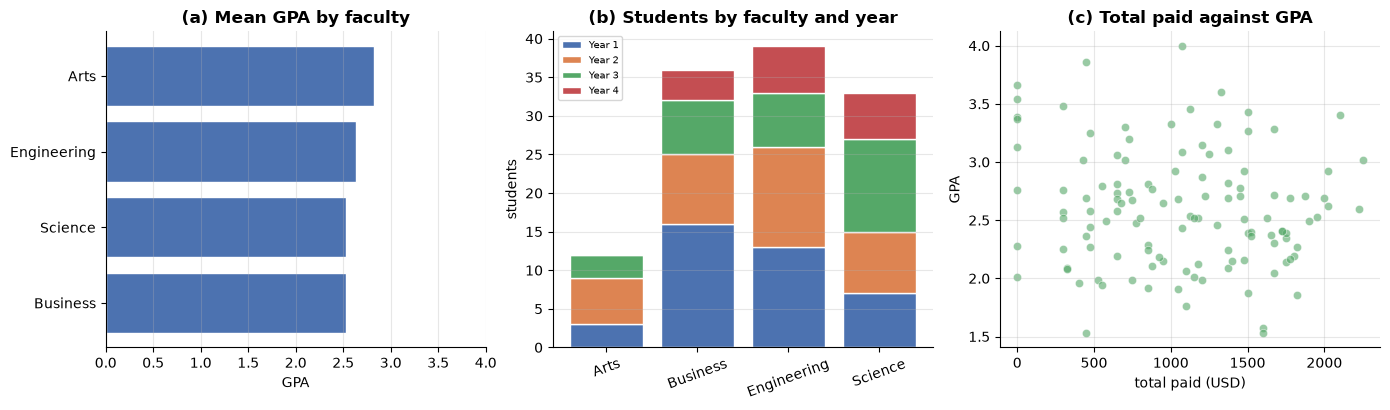

Correlation, total paid and GPA: r = -0.128
Near zero, as expected — the payment amounts were generated independently
of ability. A non-zero result here would have indicated a bug in the
data generator, which is one use for a correlation you expect to be nil.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

order = by_faculty.sort_values("mean_gpa").index
axes[0].barh(order, by_faculty.loc[order, "mean_gpa"],
             color=PALETTE[0], edgecolor="white")
axes[0].set_xlim(0, 4)
axes[0].set_title("(a) Mean GPA by faculty")
axes[0].set_xlabel("GPA")
axes[0].grid(axis="y", alpha=0)

pivot_counts = pd.crosstab(students["faculty"], students["year_level"])
bottom = np.zeros(len(pivot_counts))
for i, year in enumerate(pivot_counts.columns):
    axes[1].bar(pivot_counts.index, pivot_counts[year], bottom=bottom,
                label=f"Year {year}", color=PALETTE[i], edgecolor="white")
    bottom += pivot_counts[year].to_numpy()
axes[1].set_title("(b) Students by faculty and year")
axes[1].set_ylabel("students")
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="x", alpha=0)

axes[2].scatter(full["total_paid"], full["gpa"], s=35, alpha=0.6,
                color=PALETTE[2], edgecolor="white", linewidth=0.5)
axes[2].set_title("(c) Total paid against GPA")
axes[2].set_xlabel("total paid (USD)")
axes[2].set_ylabel("GPA")

plt.tight_layout()
plt.show()

print(f"Correlation, total paid and GPA: r = {full['total_paid'].corr(full['gpa']):.3f}")
print("Near zero, as expected — the payment amounts were generated independently")
print("of ability. A non-zero result here would have indicated a bug in the")
print("data generator, which is one use for a correlation you expect to be nil.")

---

# Part 3 - Guided workshop (in class)

Four tasks. Each has a verification cell.

### Task 1 - Filter and sort

**Problem.** Build `top_science`: the five Science students with the highest attendance, as a
DataFrame with columns `student_id`, `gpa`, `attendance_pct`, sorted by attendance descending.

**Hints**

- Filter first, then sort, then take the head or use `.nlargest(5, "attendance_pct")` after
  filtering.
- Select the three columns with a list.

**Expected output.** Five rows, followed by `Task 1 complete`.

In [22]:
# TODO 1: the five Science students with the highest attendance.
top_science = (students[students["faculty"] == "Science"]
               .nlargest(5, "attendance_pct")[["student_id", "gpa", "attendance_pct"]])

print(top_science)

   student_id   gpa  attendance_pct
44   S2026044  3.66            99.5
20   S2026020  3.60            95.1
30   S2026030  3.13            92.3
0    S2026000  3.40            90.1
53   S2026053  2.82            86.5


In [23]:
# Verification for Task 1.
expected = (students[students["faculty"] == "Science"]
            .nlargest(5, "attendance_pct")[["student_id", "gpa", "attendance_pct"]])

if top_science is None:
    print("Not complete: `top_science` is still None.")
elif not isinstance(top_science, pd.DataFrame):
    print(f"Expected a DataFrame, got {type(top_science).__name__}.")
elif list(top_science.columns) != ["student_id", "gpa", "attendance_pct"]:
    print(f"Columns should be ['student_id', 'gpa', 'attendance_pct'], "
          f"got {list(top_science.columns)}")
elif len(top_science) != 5:
    print(f"Expected 5 rows, got {len(top_science)}.")
elif not np.allclose(top_science["attendance_pct"].to_numpy(),
                     expected["attendance_pct"].to_numpy()):
    print("The rows do not match the five highest Science attendances.")
    print("Did you filter to Science before sorting?")
else:
    print("Task 1 complete.")

Task 1 complete.


### Task 2 - Aggregate with named outputs

**Problem.** Build `year_summary`: one row per `year_level`, with these columns exactly:

| Column | Value |
|---|---|
| `n` | Number of students |
| `mean_gpa` | Mean GPA |
| `max_gpa` | Highest GPA |
| `total_credits` | Sum of credits |

Use named aggregation. Keep `year_level` as the index.

**Hints**

- `df.groupby("year_level").agg(name=("column", "function"), ...)`.
- The function can be a string: `"count"`, `"mean"`, `"max"`, `"sum"`.

**Expected output.** Four rows, one per year level, followed by `Task 2 complete`.

In [24]:
# TODO 2: build the summary with named aggregation.
year_summary = students.groupby("year_level").agg(
    n=("student_id", "count"),
    mean_gpa=("gpa", "mean"),
    max_gpa=("gpa", "max"),
    total_credits=("credits", "sum"),
)

print(year_summary)

             n  mean_gpa  max_gpa  total_credits
year_level                                      
1           39  2.513590     4.00            597
2           36  2.808056     3.86            534
3           29  2.458621     3.40            441
4           16  2.562500     3.60            228


In [25]:
# Verification for Task 2.
if year_summary is None:
    print("Not complete: `year_summary` is still None.")
elif not isinstance(year_summary, pd.DataFrame):
    print(f"Expected a DataFrame, got {type(year_summary).__name__}.")
elif list(year_summary.columns) != ["n", "mean_gpa", "max_gpa", "total_credits"]:
    print(f"Columns should be ['n', 'mean_gpa', 'max_gpa', 'total_credits'], "
          f"got {list(year_summary.columns)}")
    print("Named aggregation sets the output names for you.")
elif len(year_summary) != 4:
    print(f"Expected 4 rows (one per year level), got {len(year_summary)}.")
else:
    reference = students.groupby("year_level").agg(
        n=("student_id", "count"), mean_gpa=("gpa", "mean"),
        max_gpa=("gpa", "max"), total_credits=("credits", "sum"))
    if not np.allclose(year_summary.sort_index().to_numpy().astype(float),
                       reference.sort_index().to_numpy().astype(float)):
        print("The values do not match. Check which column each function is applied to.")
    else:
        print("Task 2 complete.")

Task 2 complete.


### Task 3 - `transform` to compare against a group

**Problem.** Add two columns to `compare` (a copy of `students`):

1. `year_mean_gpa` - the mean GPA of that student's **year level**, repeated on every row.
2. `gpa_vs_year` - that student's GPA minus their year mean.

Then set `n_above` to the number of students above their own year mean.

**Hints**

- `df.groupby(key)[col].transform("mean")` gives one value per **row**.
- `.agg("mean")` would give four values and would not align.

**Expected output.** Two new columns and a count, followed by `Task 3 complete`.

In [26]:
compare = students.copy()

# TODO 3a: the mean GPA of each student's year level, one value per row.
compare["year_mean_gpa"] = compare.groupby("year_level")["gpa"].transform("mean")

# TODO 3b: the difference between the student's GPA and their year mean.
compare["gpa_vs_year"] = compare["gpa"] - compare["year_mean_gpa"]

# TODO 3c: how many students are above their own year mean?
n_above = int((compare["gpa_vs_year"] > 0).sum())

print(compare[["student_id", "year_level", "gpa", "year_mean_gpa", "gpa_vs_year"]]
      .head(6).round(3).to_string(index=False))
print(f"\nAbove their own year mean: {n_above}")

student_id  year_level  gpa  year_mean_gpa  gpa_vs_year
  S2026000           3 3.40          2.459        0.941
  S2026001           4 2.48          2.562       -0.083
  S2026002           3 2.09          2.459       -0.369
  S2026003           2 2.69          2.808       -0.118
  S2026004           2 2.71          2.808       -0.098
  S2026005           2 3.28          2.808        0.472

Above their own year mean: 56


In [27]:
# Verification for Task 3.
reference_mean = students.groupby("year_level")["gpa"].transform("mean")
reference_diff = students["gpa"] - reference_mean
reference_above = int((reference_diff > 0).sum())

problems = []
if compare["year_mean_gpa"].isna().all():
    problems.append("year_mean_gpa was not filled in")
elif not np.allclose(compare["year_mean_gpa"].to_numpy(dtype=float),
                     reference_mean.to_numpy()):
    problems.append("year_mean_gpa does not match the per-year mean "
                    "(did you use transform, not agg?)")

if compare["gpa_vs_year"].isna().all():
    problems.append("gpa_vs_year was not filled in")
elif not np.allclose(compare["gpa_vs_year"].to_numpy(dtype=float),
                     reference_diff.to_numpy()):
    problems.append("gpa_vs_year should be gpa minus year_mean_gpa")

if n_above is None:
    problems.append("n_above is still None")
elif int(n_above) != reference_above:
    problems.append(f"n_above should be {reference_above}, got {n_above}")

if problems:
    print("Not complete:")
    for p in problems:
        print("  -", p)
else:
    print(f"Task 3 complete. {n_above} students are above their own year mean.")

Task 3 complete. 56 students are above their own year mean.


### Task 4 - Join safely

**Problem.** Attach each student's total payments to the student table.

1. Build `payment_totals`: one row per `student_id`, with `total_paid` (sum of `amount_usd`)
   and `n_payments` (count).
2. Merge it onto `students` with a **left** join, keeping every student.
3. Pass `validate` with the correct relationship.
4. Fill the missing totals for students who never paid: `0.0` and `0`.

Store the result in `student_payments`.

**Hints**

- Aggregate first, then merge. Merging the raw `payments` table would multiply rows.
- After aggregation, `payment_totals` has unique keys and `students` has unique keys, so the
  relationship is `"one_to_one"`.
- `reset_index()` after the groupby, so `student_id` is a column to merge on.

**Expected output.** The same number of rows as `students`, followed by `Task 4 complete`.

In [28]:
# TODO 4a: one row per student, with total_paid and n_payments.
payment_totals = (payments.groupby("student_id")
                  .agg(total_paid=("amount_usd", "sum"),
                       n_payments=("amount_usd", "count"))
                  .reset_index())

# TODO 4b: left-join onto students, with the right validate value.
student_payments = students.merge(payment_totals, on="student_id",
                                  how="left", validate="one_to_one")

# TODO 4c: fill the missing totals with 0.0 and 0.
student_payments["total_paid"] = student_payments["total_paid"].fillna(0.0)
student_payments["n_payments"] = student_payments["n_payments"].fillna(0).astype(int)

if student_payments is not None:
    print(f"students        : {len(students)} rows")
    print(f"student_payments: {len(student_payments)} rows")
    print(student_payments[["student_id", "faculty", "total_paid", "n_payments"]]
          .head(6).to_string(index=False))

students        : 120 rows
student_payments: 120 rows
student_id     faculty  total_paid  n_payments
  S2026000     Science      2100.0           3
  S2026001    Business       775.0           1
  S2026002        Arts      1375.0           3
  S2026003     Science      1775.0           3
  S2026004 Engineering      1225.0           2
  S2026005        Arts      1675.0           3


In [29]:
# Verification for Task 4.
if student_payments is None:
    print("Not complete: `student_payments` is still None.")
elif len(student_payments) != len(students):
    print(f"Expected {len(students)} rows, got {len(student_payments)}.")
    if len(student_payments) > len(students):
        print("More rows than students means the join multiplied them —")
        print("aggregate `payments` to one row per student BEFORE merging.")
    else:
        print("Fewer rows means an inner join dropped the students who never paid.")
else:
    problems = []
    for column in ["total_paid", "n_payments"]:
        if column not in student_payments.columns:
            problems.append(f"missing column {column!r}")
    if not problems:
        if student_payments[["total_paid", "n_payments"]].isna().any().any():
            problems.append("some totals are still NaN — fill them with 0")
        else:
            reference = (payments.groupby("student_id")["amount_usd"].sum()
                         .reindex(students["student_id"]).fillna(0.0))
            got = student_payments.set_index("student_id")["total_paid"]
            if not np.allclose(got.reindex(students["student_id"]).to_numpy(),
                               reference.to_numpy()):
                problems.append("total_paid does not match the per-student sums")
            n_zero = int((student_payments["n_payments"] == 0).sum())
            if n_zero == 0:
                problems.append("no student has n_payments == 0; some students "
                                "never paid and must be kept by the left join")
    if problems:
        print("Not complete:")
        for p in problems:
            print("  -", p)
    else:
        print(f"Task 4 complete. {len(student_payments)} rows, "
              f"{int((student_payments['n_payments'] == 0).sum())} students with no payment.")

Task 4 complete. 120 rows, 8 students with no payment.


---

# Part 4 - Homework

Run **Restart Kernel and Run All Cells** before submitting, then push to your
`puc-data-analysis` repository.

## Problem 1 - A flexible summary function

**Problem.** Write `summarise_by(df, group_cols, specs)`, a reusable wrapper around named
aggregation.

**Requirements**

| Parameter | Meaning |
|---|---|
| `df` | The frame to summarise |
| `group_cols` | A string or a list of strings to group by |
| `specs` | A dict mapping `output_name -> (input_column, function)` |

Return a `DataFrame` with:

- one row per group,
- the grouping columns as **ordinary columns**, not as the index,
- the summary columns in the order given by `specs`,
- an extra final column `n_rows` holding the number of rows in each group,
- rows sorted by the grouping columns, ascending.

**Requirements on errors**

- Raise `KeyError` if any grouping column is absent from `df`.
- Raise `KeyError` if any input column named in `specs` is absent from `df`.
- Raise `ValueError` if `specs` is empty.

Do not modify the input frame.

**Hints**

- Accept a string for `group_cols` by converting it: `[group_cols] if isinstance(group_cols, str) else list(group_cols)`.
- `df.groupby(cols, as_index=False)` keeps the grouping columns as columns.
- Named aggregation takes keyword arguments, so build a dict and pass it with `**`:
  `df.groupby(...).agg(**named)`.
- `n_rows` is `(any_grouping_column, "size")`. Add it to the dict last so it lands last.
- Validate everything **before** the groupby, so the error names the real problem.

In [30]:
# Problem 1 — starter code.

def summarise_by(df: pd.DataFrame, group_cols, specs: dict) -> pd.DataFrame:
    """Group a frame and apply named aggregations.

    Parameters
    ----------
    df : pandas.DataFrame
        The frame to summarise. Not modified.
    group_cols : str or list of str
        Column(s) to group by.
    specs : dict
        Maps output_name -> (input_column, function).

    Returns
    -------
    pandas.DataFrame
        One row per group, grouping columns first, then the summaries,
        then n_rows.

    Raises
    ------
    KeyError
        If a named column is absent.
    ValueError
        If specs is empty.
    """
    if not specs:
        raise ValueError("specs cannot be empty")

    cols = [group_cols] if isinstance(group_cols, str) else list(group_cols)

    for col in cols:
        if col not in df.columns:
            raise KeyError(f"Grouping column {col!r} is not in df")

    for out_name, (in_col, func) in specs.items():
        if in_col not in df.columns:
            raise KeyError(f"Input column {in_col!r} in specs is not in df")

    agg_dict = dict(specs)
    agg_dict["n_rows"] = (cols[0], "size")

    res = df.groupby(cols, as_index=False, sort=True).agg(**agg_dict)
    res = res.sort_values(cols).reset_index(drop=True)
    return res


out = summarise_by(students, "faculty", {
    "mean_gpa": ("gpa", "mean"),
    "max_gpa": ("gpa", "max"),
    "total_credits": ("credits", "sum"),
})
print(out.round(2))

print("\nGrouped by two columns:")
print(summarise_by(students, ["faculty", "year_level"],
                   {"mean_gpa": ("gpa", "mean")}).round(2).head(6))

       faculty  mean_gpa  max_gpa  total_credits  n_rows
0         Arts      2.82     3.54            183      12
1     Business      2.53     4.00            552      36
2  Engineering      2.63     3.86            585      39
3      Science      2.53     3.66            480      33

Grouped by two columns:
    faculty  year_level  mean_gpa  n_rows
0      Arts           1      2.55       3
1      Arts           2      3.24       6
2      Arts           3      2.25       3
3  Business           1      2.63      16
4  Business           2      2.64       9
5  Business           3      2.40       7


In [31]:
# Problem 1 — validation. All assertions must pass.

sample = pd.DataFrame({
    "team":   ["A", "A", "B", "B", "B", "C"],
    "region": ["N", "N", "N", "S", "S", "S"],
    "score":  [10.0, 20.0, 5.0, 7.0, 9.0, 4.0],
    "units":  [1, 2, 3, 4, 5, 6],
})

out = summarise_by(sample, "team", {"mean_score": ("score", "mean")})

# --- structure ---
assert isinstance(out, pd.DataFrame), "summarise_by must return a DataFrame"
assert list(out.columns) == ["team", "mean_score", "n_rows"], (
    f"Columns should be the grouping column, then the specs, then n_rows; "
    f"got {list(out.columns)}"
)
assert isinstance(out.index, pd.RangeIndex), (
    "Grouping columns must be ordinary columns, not the index — use as_index=False "
    "or reset_index()"
)
assert len(out) == 3, f"Three teams, so three rows; got {len(out)}"

# --- values ---
assert out["team"].tolist() == ["A", "B", "C"], "Rows must be sorted by the grouping column"
assert np.isclose(out.loc[0, "mean_score"], 15.0)
assert out["n_rows"].tolist() == [2, 3, 1], f"n_rows should be [2, 3, 1]; got {out['n_rows'].tolist()}"

# --- spec order is preserved, and n_rows is last ---
multi = summarise_by(sample, "team", {
    "total": ("score", "sum"),
    "biggest": ("score", "max"),
    "units": ("units", "sum"),
})
assert list(multi.columns) == ["team", "total", "biggest", "units", "n_rows"], (
    f"Summary columns must follow the order of `specs`; got {list(multi.columns)}"
)

# --- grouping by several columns ---
two = summarise_by(sample, ["team", "region"], {"mean_score": ("score", "mean")})
assert list(two.columns) == ["team", "region", "mean_score", "n_rows"]
assert len(two) == 4, f"A/N, B/N, B/S, C/S is four groups; got {len(two)}"
assert two["team"].tolist() == ["A", "B", "B", "C"], "Sorted by the grouping columns"

# --- a string and a one-element list behave the same ---
as_string = summarise_by(sample, "team", {"m": ("score", "mean")})
as_list = summarise_by(sample, ["team"], {"m": ("score", "mean")})
assert as_string.equals(as_list), "A string group_cols must behave like a one-element list"

# --- the input is untouched ---
before = sample.copy()
_ = summarise_by(sample, "team", {"m": ("score", "mean")})
assert sample.equals(before), "summarise_by must not modify its input"

# --- errors ---
try:
    summarise_by(sample, "nope", {"m": ("score", "mean")})
except KeyError:
    pass
else:
    raise AssertionError("A missing grouping column must raise KeyError")

try:
    summarise_by(sample, "team", {"m": ("nope", "mean")})
except KeyError:
    pass
else:
    raise AssertionError("A missing input column in specs must raise KeyError")

try:
    summarise_by(sample, "team", {})
except ValueError:
    pass
else:
    raise AssertionError("An empty specs dict must raise ValueError")

# --- it works on the notebook's own data ---
real = summarise_by(students, "faculty", {"mean_gpa": ("gpa", "mean")})
assert len(real) == students["faculty"].nunique()
assert real["n_rows"].sum() == len(students), "n_rows must account for every input row"

print("Problem 1: all assertions passed.")

Problem 1: all assertions passed.


---

## Problem 2 - A merge that refuses to corrupt your data

§2.8 showed a join silently multiplying rows. This function makes that impossible to miss.

**Problem.** Write `safe_merge(left, right, on, how="left", expect=None)`.

**Requirements.** Return a tuple `(merged, report)` where `report` is a dictionary with
exactly these keys:

| Key | Type | Value |
|---|---|---|
| `rows_left` | `int` | Rows in `left` |
| `rows_right` | `int` | Rows in `right` |
| `rows_out` | `int` | Rows in the result |
| `row_change` | `int` | `rows_out - rows_left` |
| `left_unique` | `bool` | Whether the key is unique in `left` |
| `right_unique` | `bool` | Whether the key is unique in `right` |
| `unmatched_left` | `int` | Keys in `left` with no match in `right` |
| `exploded` | `bool` | `True` if `rows_out > rows_left` |

**Requirements on behaviour**

- If `expect` is given, pass it to `pd.merge` as `validate`. A violation therefore raises
  `pd.errors.MergeError`, which must **not** be caught.
- Raise `KeyError` if `on` is absent from either frame.
- `unmatched_left` counts **distinct keys**, not rows.
- Do not modify either input frame.

**Hints**

- `series.is_unique` answers the uniqueness question directly.
- `left[on].nunique()` versus the number of left keys found in `right[on]`: use
  `~left[on].isin(right[on])` and count the distinct keys, not the rows.
- Compute everything from the inputs **before** merging, so the report describes the inputs
  rather than the output.
- `pd.merge(..., validate=expect)` accepts `None`, which means no check — so you can pass it
  through unconditionally.

In [32]:
# Problem 2 — starter code.

def safe_merge(left: pd.DataFrame, right: pd.DataFrame, on: str,
               how: str = "left", expect=None) -> tuple:
    """Merge two frames and report what the join did to the row count.

    Parameters
    ----------
    left, right : pandas.DataFrame
        Frames to join. Neither is modified.
    on : str
        The key column, which must exist in both.
    how : str
        Join type, passed to pd.merge.
    expect : str or None
        Passed to pd.merge as `validate`. A violation raises MergeError.

    Returns
    -------
    (pandas.DataFrame, dict)

    Raises
    ------
    KeyError
        If `on` is absent from either frame.
    pandas.errors.MergeError
        If `expect` is given and the relationship does not hold.
    """
    if on not in left.columns:
        raise KeyError(f"Key column {on!r} is absent from left frame")
    if on not in right.columns:
        raise KeyError(f"Key column {on!r} is absent from right frame")

    rows_left = int(len(left))
    rows_right = int(len(right))
    left_unique = bool(left[on].is_unique)
    right_unique = bool(right[on].is_unique)

    unmatched_mask = ~left[on].isin(right[on])
    unmatched_left = int(left.loc[unmatched_mask, on].nunique())

    merged = pd.merge(left, right, on=on, how=how, validate=expect)
    rows_out = int(len(merged))
    row_change = int(rows_out - rows_left)
    exploded = bool(rows_out > rows_left)

    report = {
        "rows_left": rows_left,
        "rows_right": rows_right,
        "rows_out": rows_out,
        "row_change": row_change,
        "left_unique": left_unique,
        "right_unique": right_unique,
        "unmatched_left": unmatched_left,
        "exploded": exploded,
    }
    return merged, report


merged, report = safe_merge(students, faculty_info, on="faculty",
                            how="left", expect="many_to_one")
print("A well-behaved lookup join:")
for key, value in report.items():
    print(f"  {key:<16} {value}")

A well-behaved lookup join:
  rows_left        120
  rows_right       4
  rows_out         120
  row_change       0
  left_unique      False
  right_unique     True
  unmatched_left   0
  exploded         False


In [33]:
# Problem 2 — validation. All assertions must pass.

left_frame = pd.DataFrame({
    "key": ["a", "b", "c", "d"],
    "value": [1, 2, 3, 4],
})
right_clean = pd.DataFrame({
    "key": ["a", "b", "c"],
    "label": ["A", "B", "C"],
})
right_dupes = pd.DataFrame({
    "key": ["a", "a", "b"],
    "label": ["A1", "A2", "B"],
})

# --- a clean many-to-one join ---
merged, report = safe_merge(left_frame, right_clean, on="key", how="left")

assert isinstance(merged, pd.DataFrame), "The first return value must be a DataFrame"
assert isinstance(report, dict), "The second return value must be a dict"

expected_keys = {"rows_left", "rows_right", "rows_out", "row_change",
                 "left_unique", "right_unique", "unmatched_left", "exploded"}
assert set(report.keys()) == expected_keys, (
    f"Report keys must be exactly {sorted(expected_keys)}; got {sorted(report.keys())}"
)

assert report["rows_left"] == 4
assert report["rows_right"] == 3
assert report["rows_out"] == 4, "A left join on unique keys keeps the left row count"
assert report["row_change"] == 0
assert report["left_unique"] is True
assert report["right_unique"] is True
assert report["unmatched_left"] == 1, "'d' has no match in right_clean"
assert report["exploded"] is False

for key in ["left_unique", "right_unique", "exploded"]:
    assert isinstance(report[key], bool), f"{key} must be a Python bool"
for key in ["rows_left", "rows_right", "rows_out", "row_change", "unmatched_left"]:
    assert isinstance(report[key], int), f"{key} must be a Python int"

# --- a join that explodes, detected and reported ---
merged2, report2 = safe_merge(left_frame, right_dupes, on="key", how="left")
assert report2["right_unique"] is False, "right_dupes has a repeated key"
assert report2["rows_out"] == 5, (
    f"'a' appears twice on the right, so it produces 2 rows; total 5. Got {report2['rows_out']}"
)
assert report2["row_change"] == 1
assert report2["exploded"] is True, "rows_out > rows_left must set exploded"

# --- validate is passed through and is NOT caught ---
try:
    safe_merge(left_frame, right_dupes, on="key", how="left", expect="many_to_one")
except pd.errors.MergeError:
    pass
else:
    raise AssertionError(
        "With expect='many_to_one' and duplicate right keys, MergeError must propagate"
    )

# --- a valid expectation does not raise ---
merged3, report3 = safe_merge(left_frame, right_clean, on="key",
                              how="left", expect="one_to_one")
assert report3["rows_out"] == 4

# --- unmatched_left counts DISTINCT KEYS, not rows ---
left_repeats = pd.DataFrame({"key": ["x", "x", "y"], "v": [1, 2, 3]})
_, report4 = safe_merge(left_repeats, right_clean, on="key", how="left")
assert report4["left_unique"] is False
assert report4["unmatched_left"] == 2, (
    f"'x' and 'y' are both unmatched — 2 distinct keys, not 3 rows. "
    f"Got {report4['unmatched_left']}"
)

# --- a missing key column raises KeyError ---
for bad_left, bad_right in [(left_frame.rename(columns={"key": "k"}), right_clean),
                            (left_frame, right_clean.rename(columns={"key": "k"}))]:
    try:
        safe_merge(bad_left, bad_right, on="key")
    except KeyError:
        pass
    else:
        raise AssertionError("A missing key column must raise KeyError")

# --- inputs are untouched ---
before_left, before_right = left_frame.copy(), right_clean.copy()
_ = safe_merge(left_frame, right_clean, on="key")
assert left_frame.equals(before_left) and right_clean.equals(before_right), (
    "safe_merge must not modify its inputs"
)

# --- it works on the notebook's own tables ---
real_merged, real_report = safe_merge(students, faculty_info, on="faculty",
                                      how="left", expect="many_to_one")
assert real_report["exploded"] is False
assert real_report["rows_out"] == len(students)
assert real_report["unmatched_left"] == 0, "Every faculty appears in the lookup"

print("Problem 2: all assertions passed.")

Problem 2: all assertions passed.


---

## Submission checklist

- [Done] All four workshop tasks print their `complete` message.
- [Done] Problem 1 prints `all assertions passed`.
- [Done] Problem 2 prints `all assertions passed`.
- [Done] **Restart Kernel and Run All Cells** completes with no errors.
- [Done] Committed and pushed to your `puc-data-analysis` repository.

## Looking ahead to Week 7

Week 7 begins visualization properly: matplotlib's figure and axes model, and the four chart
types that answer most questions. The summary tables you built today are what those charts
will be drawn from.

Before the session, read McKinney §9.1 and Pfaffelhuber §8.1–8.5.

---

## References

McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
§8.1–8.3, §10.1–10.5.

Pfaffelhuber, P. *Python for Data Analysis* (course notes). §7.2–7.6.
Available at `https://pfaffelh.github.io/python_for_data/`.